# Trabajo Práctico Integrador – Introducción al Análisis de Datos
## Entrega 4: Análisis Exploratorio de Datos

**Apellido y nombre:** Aguillón, Fernando  
**Comisión:** 5  
**Dataset:** E – reservas hoteleras  
**Entrega:** 4  
**Recorrido elegido:** SQL + R


## 1. Objetivo y continuidad

Se estudian diferencias entre reservas canceladas y no canceladas. La variable objetivo es `is_canceled`. La unidad de análisis es **una reserva hotelera por fila**: cada registro representa una reserva, no una persona ni un hotel.

Se retoman los criterios corregidos de la Entrega 2: conservar `lead_time`, `stays_in_week_nights`, `meal`, `distribution_channel` y `agent`; reemplazar faltantes de `children` por cero; identificar faltantes de `agent` y `country`; eliminar solo `adr < 0`; conservar `adr = 0`, valores extremos y reservas sin huéspedes, marcando estas últimas sin eliminarlas. Se quitan duplicados exactos, `booking_id` y `company`.

### Preguntas formuladas

1. ¿La proporción de cancelaciones difiere entre City Hotel y Resort Hotel?
2. ¿La distribución de `adr` difiere entre reservas canceladas y no canceladas?
3. ¿La distribución de `lead_time` difiere entre reservas canceladas y no canceladas?



## 2. Librerías y entorno SQL



In [7]:
options(HTTPUserAgent = sprintf(
  "R/%s R (%s)",
  getRversion(),
  paste(getRversion(), R.version["platform"], R.version["arch"], R.version["os"])
))

install.packages(
  "duckdb",
  repos = "https://p3m.dev/cran/__linux__/manylinux_2_28/latest/"
)

library(duckdb)

packageVersion("duckdb")

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



[1] ‘2.0.0’

In [8]:
library(DBI)
library(duckdb)
library(dplyr)
library(ggplot2)
library(scales)

cat("Todos los paquetes se cargaron correctamente.\n")

Todos los paquetes se cargaron correctamente.


## 3. Carga del CSV original



In [9]:
ruta_csv <- "/content/hotel booking TPI grupo E.csv"
if (!file.exists(ruta_csv)) {
  stop("No se encontró el CSV. Subí 'hotel booking TPI grupo E.csv' a /content/ y volvé a ejecutar.")
}
datos_originales <- read.csv(
  ruta_csv, stringsAsFactors = FALSE,
  na.strings = c("", "NA"), check.names = FALSE
)
cat("Filas originales:", nrow(datos_originales), "\\n")
cat("Columnas originales:", ncol(datos_originales), "\\n")


Filas originales: 25000 \nColumnas originales: 32 \n

## 4. Preparación mínima y documentada

Se aplican las decisiones corregidas de la Entrega 2.


In [10]:
df <- datos_originales
filas_iniciales <- nrow(df)
duplicados <- sum(duplicated(df))
faltantes_children <- if ("children" %in% names(df)) sum(is.na(df$children)) else NA
adr_negativos <- if ("adr" %in% names(df)) sum(df$adr < 0, na.rm = TRUE) else NA
adr_ceros <- if ("adr" %in% names(df)) sum(df$adr == 0, na.rm = TRUE) else NA

df <- df[!duplicated(df), ]
df <- df[, !(names(df) %in% intersect(c("booking_id", "company"), names(df))), drop = FALSE]

if ("children" %in% names(df)) df$children[is.na(df$children)] <- 0
if ("agent" %in% names(df)) {
  df$agent <- as.character(df$agent)
  df$agent[is.na(df$agent) | trimws(df$agent) == ""] <- "Sin agente"
}
if ("country" %in% names(df)) {
  df$country <- as.character(df$country)
  df$country[is.na(df$country) | trimws(df$country) == ""] <- "Sin especificar"
}
if ("adr" %in% names(df)) df <- df[is.na(df$adr) | df$adr >= 0, , drop = FALSE]

if (all(c("adults", "children", "babies") %in% names(df))) {
  df$reserva_sin_huespedes <- with(df, adults == 0 & children == 0 & babies == 0)
}
if (all(c("stays_in_week_nights", "stays_in_weekend_nights") %in% names(df))) {
  df$total_nights <- df$stays_in_week_nights + df$stays_in_weekend_nights
}
if (all(c("adults", "children", "babies") %in% names(df))) {
  df$total_guests <- df$adults + df$children + df$babies
}

cat("Duplicados exactos eliminados:", duplicados)
cat("Faltantes originales de children:", faltantes_children)
cat("ADR negativos detectados:", adr_negativos)
cat("ADR igual a cero conservados antes del filtro:", adr_ceros)
cat("Filas finales:", nrow(df))
cat("Diferencia de filas:", filas_iniciales - nrow(df))


Duplicados exactos eliminados: 0Faltantes originales de children: 2ADR negativos detectados: 1ADR igual a cero conservados antes del filtro: 402Filas finales: 24999Diferencia de filas: 1

## 5. Revisión inicial

### 5.1 Variable objetivo y controles

`is_canceled` representa el estado de cancelación: `0` = no cancelada y `1` = cancelada. Se verifica que los valores presentes coincidan con esa codificación.


In [11]:
requeridas <- c("hotel", "is_canceled", "adr", "lead_time")
faltantes <- setdiff(requeridas, names(df))
if (length(faltantes) > 0) stop(paste("Faltan columnas:", paste(faltantes, collapse = ", ")))

df$is_canceled <- as.integer(as.character(df$is_canceled))
df$hotel <- as.character(df$hotel)
df$adr <- as.numeric(df$adr)
df$lead_time <- as.numeric(df$lead_time)

if (!all(na.omit(unique(df$is_canceled)) %in% c(0L, 1L))) {
  stop("is_canceled contiene valores distintos de 0 y 1. Revisar codificación.")
}


### 5.2 Tabla SQL y estructura

Se crea la tabla `reservas`. Las consultas siguientes verifican columnas, tipos, cantidad de filas y primeras observaciones.


In [12]:
conexion <- DBI::dbConnect(duckdb::duckdb(), dbdir = ":memory:")
DBI::dbWriteTable(conexion, "reservas", df, overwrite = TRUE)

estructura <- DBI::dbGetQuery(conexion, "DESCRIBE reservas")
estructura

DBI::dbGetQuery(conexion, "SELECT COUNT(*) AS cantidad_filas FROM reservas")

DBI::dbGetQuery(conexion, "SELECT * FROM reservas LIMIT 10")


duckdb keeps downloaded extensions and secrets in a temporary directory:
ℹ /tmp/RtmplsACAZ/duckdb
This is removed when the R session ends.
• Extensions are re-downloaded each session.
• Secrets are lost.
ℹ Run duckdb(shared_home = TRUE) (or create ~/.duckdb) to keep them (suitable for most users).
ℹ Run duckdb(shared_home = FALSE) to accept the temporary directory (and silence this message).
ℹ See ?duckdb_storage for details and alternatives.


column_name,column_type,null,key,default,extra
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
hotel,VARCHAR,YES,NA,NA,NA
is_canceled,INTEGER,YES,NA,NA,NA
lead_time,DOUBLE,YES,NA,NA,NA
arrival_date_year,INTEGER,YES,NA,NA,NA
arrival_date_month,VARCHAR,YES,NA,NA,NA
arrival_date_week_number,INTEGER,YES,NA,NA,NA
arrival_date_day_of_month,INTEGER,YES,NA,NA,NA
arrival_date,VARCHAR,YES,NA,NA,NA
stays_in_weekend_nights,INTEGER,YES,NA,NA,NA


cantidad_filas
<dbl>
24999


hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,arrival_date,stays_in_weekend_nights,stays_in_week_nights,⋯,deposit_type,agent,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reserva_sin_huespedes,total_nights,total_guests
<chr>,<int>,<dbl>,<int>,<chr>,<int>,<int>,<chr>,<int>,<int>,⋯,<chr>,<chr>,<int>,<chr>,<dbl>,<int>,<int>,<lgl>,<int>,<dbl>
City Hotel,0,2,2025,January,2,12,2025-01-12,0,1,⋯,No Deposit,14,0,Transient,150.00,0,2,FALSE,1,2
Resort Hotel,0,1,2024,February,8,20,2024-02-20,0,1,⋯,No Deposit,240,0,Transient,48.00,0,0,FALSE,1,2
City Hotel,1,28,2025,August,32,9,2025-08-09,0,2,⋯,No Deposit,9,0,Transient,190.00,0,0,FALSE,2,2
Resort Hotel,0,31,2024,February,8,19,2024-02-19,2,3,⋯,No Deposit,241,0,Transient,76.38,0,2,FALSE,5,3
Resort Hotel,0,204,2025,August,35,29,2025-08-29,4,10,⋯,No Deposit,250,0,Transient,153.57,0,3,FALSE,14,2
Resort Hotel,1,172,2023,August,31,4,2023-08-04,1,5,⋯,No Deposit,250,0,Transient,125.90,0,1,FALSE,6,2
City Hotel,1,272,2023,July,28,16,2023-07-16,0,2,⋯,No Deposit,1,0,Transient-Party,62.80,0,0,FALSE,2,2
City Hotel,0,138,2024,August,32,9,2024-08-09,0,5,⋯,No Deposit,7,0,Transient,101.49,0,1,FALSE,5,3
City Hotel,0,56,2025,April,15,10,2025-04-10,1,2,⋯,No Deposit,14,0,Transient,195.00,1,3,FALSE,3,3


### 5.3 Distribución inicial de `is_canceled`

La tabla informa frecuencias absolutas y porcentajes. El porcentaje se calcula sobre los registros agrupados por estado.


In [13]:
frecuencia_objetivo <- DBI::dbGetQuery(
  conexion,
  "
  SELECT is_canceled,
         CASE WHEN is_canceled = 0 THEN 'No cancelada'
              WHEN is_canceled = 1 THEN 'Cancelada'
              ELSE 'Sin dato' END AS estado,
         COUNT(*) AS cantidad,
         ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS porcentaje
  FROM reservas
  GROUP BY is_canceled
  ORDER BY is_canceled
  "
)
frecuencia_objetivo


is_canceled,estado,cantidad,porcentaje
<int>,<chr>,<dbl>,<dbl>
0,No cancelada,15738,62.95
1,Cancelada,9261,37.05


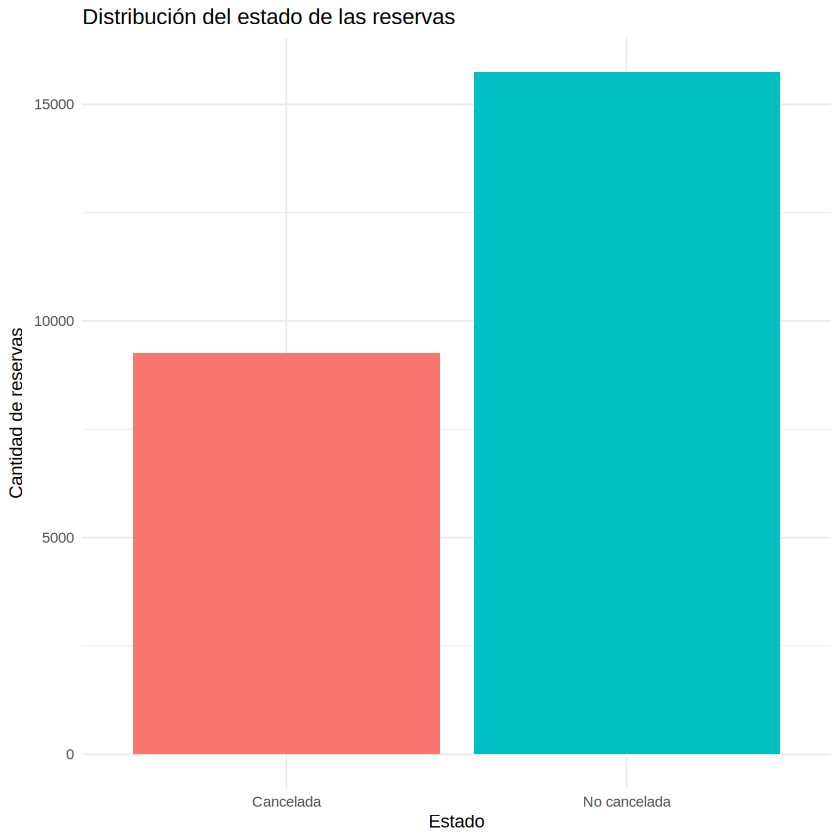

In [14]:
ggplot(frecuencia_objetivo, aes(x = estado, y = cantidad, fill = estado)) +
  geom_col(show.legend = FALSE) +
  labs(title = "Distribución del estado de las reservas",
       x = "Estado", y = "Cantidad de reservas") +
  theme_minimal()


**Interpretación:** la tabla muestra cuántas reservas corresponden a cada estado y qué porcentaje representan. El gráfico permite observar si las categorías están equilibradas o si una concentra más casos.

### 5.4 Variables seleccionadas y resúmenes individuales

Se seleccionan cuatro variables centrales:

- `is_canceled`: binaria; variable objetivo.
- `hotel`: categórica; permite comparar tipos de hotel.
- `adr`: cuantitativa; tarifa promedio por noche.
- `lead_time`: cuantitativa; días entre la reserva y la llegada.

**Resumen cuantitativo de `lead_time`:**


In [15]:
DBI::dbGetQuery(
  conexion,
  "
  SELECT COUNT(lead_time) AS cantidad,
         AVG(lead_time) AS media,
         MEDIAN(lead_time) AS mediana,
         STDDEV_SAMP(lead_time) AS desvio,
         QUANTILE_CONT(lead_time, 0.25) AS q1,
         QUANTILE_CONT(lead_time, 0.75) AS q3,
         MIN(lead_time) AS minimo,
         MAX(lead_time) AS maximo
  FROM reservas
  "
)


cantidad,media,mediana,desvio,q1,q3,minimo,maximo
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
24999,103.9191,69,107.5008,18,159,0,629


**Frecuencia de la variable categórica `hotel`:**


In [16]:
frecuencia_hotel <- DBI::dbGetQuery(
  conexion,
  "
  SELECT hotel, COUNT(*) AS cantidad,
         ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS porcentaje
  FROM reservas
  GROUP BY hotel
  ORDER BY cantidad DESC
  "
)
frecuencia_hotel


hotel,cantidad,porcentaje
<chr>,<dbl>,<dbl>
City Hotel,16611,66.45
Resort Hotel,8388,33.55


### 5.5 Visualizaciones individuales iniciales

Los histogramas permiten observar la distribución de las variables cuantitativas; el gráfico de barras, la frecuencia de la variable categórica.


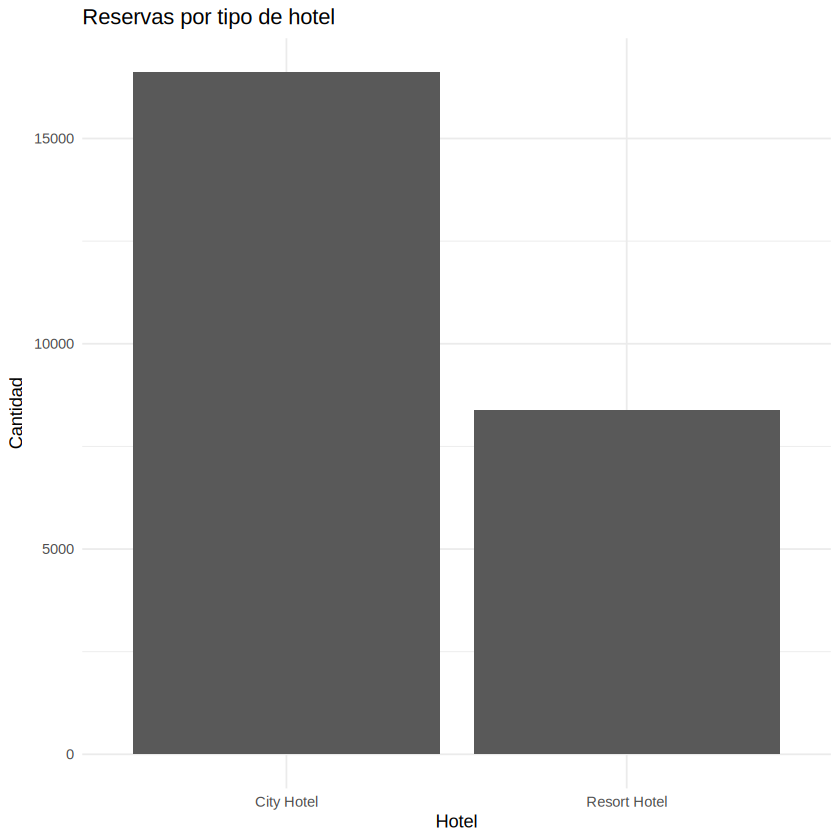

In [17]:
ggplot(df, aes(x = hotel)) +
  geom_bar() +
  labs(title = "Reservas por tipo de hotel", x = "Hotel", y = "Cantidad") +
  theme_minimal()


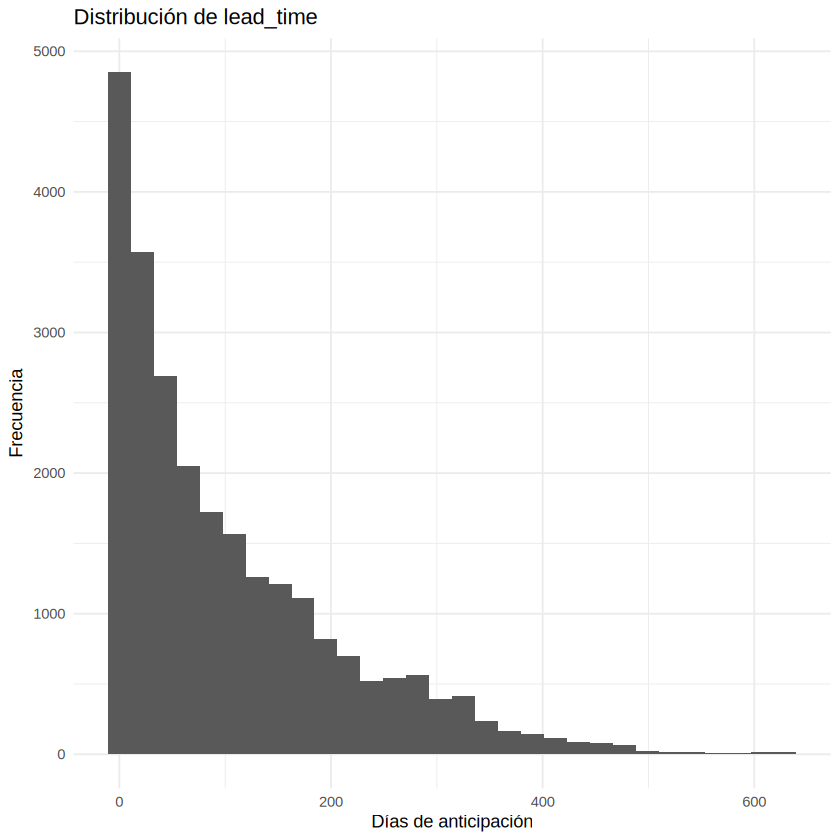

In [18]:
ggplot(df, aes(x = lead_time)) +
  geom_histogram(bins = 30, na.rm = TRUE) +
  labs(title = "Distribución de lead_time",
       x = "Días de anticipación", y = "Frecuencia") +
  theme_minimal()


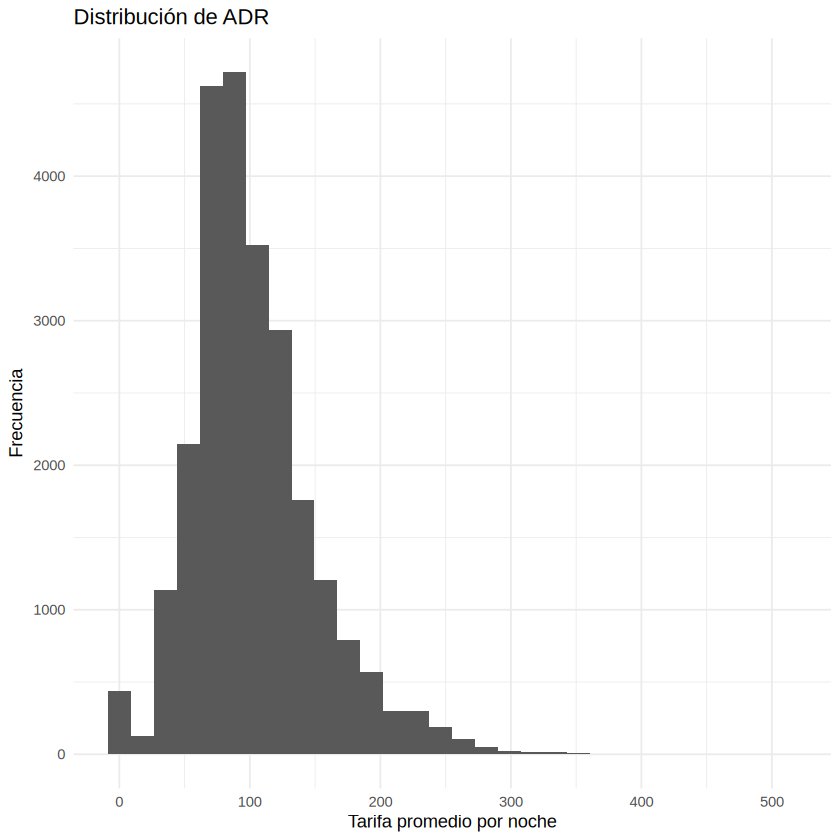

In [19]:
ggplot(df, aes(x = adr)) +
  geom_histogram(bins = 30, na.rm = TRUE) +
  labs(title = "Distribución de ADR",
       x = "Tarifa promedio por noche", y = "Frecuencia") +
  theme_minimal()


**Interpretación inicial:** el gráfico de barras compara el volumen de reservas por hotel. Los histogramas muestran la forma de las distribuciones de anticipación y tarifa, permitiendo observar asimetrías y posibles valores alejados del centro. Son distribuciones individuales; todavía no comparan los estados de cancelación.


### 5.6 Preguntas exploratorias formuladas

1. ¿La proporción de cancelaciones difiere entre City Hotel y Resort Hotel?
2. ¿La distribución de `adr` presenta diferencias entre reservas canceladas y no canceladas?
3. ¿La distribución de `lead_time` presenta diferencias entre reservas canceladas y no canceladas?



## 6. Comparaciones mediante SQL

Cada consulta informa tamaños de grupo y medidas descriptivas. Las proporciones se calculan dentro de cada grupo, no sobre el total general.


### Pregunta 1. Tipo de hotel y cancelación

¿La proporción de cancelaciones difiere según el tipo de hotel?


In [20]:
comparacion_hotel <- DBI::dbGetQuery(
  conexion,
  "
  SELECT hotel,
         COUNT(*) AS total_reservas,
         SUM(CASE WHEN is_canceled = 1 THEN 1 ELSE 0 END) AS canceladas,
         SUM(CASE WHEN is_canceled = 0 THEN 1 ELSE 0 END) AS no_canceladas,
         ROUND(100.0 * SUM(CASE WHEN is_canceled = 1 THEN 1 ELSE 0 END)
               / COUNT(*), 2) AS porcentaje_canceladas
  FROM reservas
  WHERE is_canceled IN (0, 1)
  GROUP BY hotel
  ORDER BY hotel
  "
)
comparacion_hotel


hotel,total_reservas,canceladas,no_canceladas,porcentaje_canceladas
<chr>,<dbl>,<dbl>,<dbl>,<dbl>
City Hotel,16611,6933,9678,41.74
Resort Hotel,8388,2328,6060,27.75


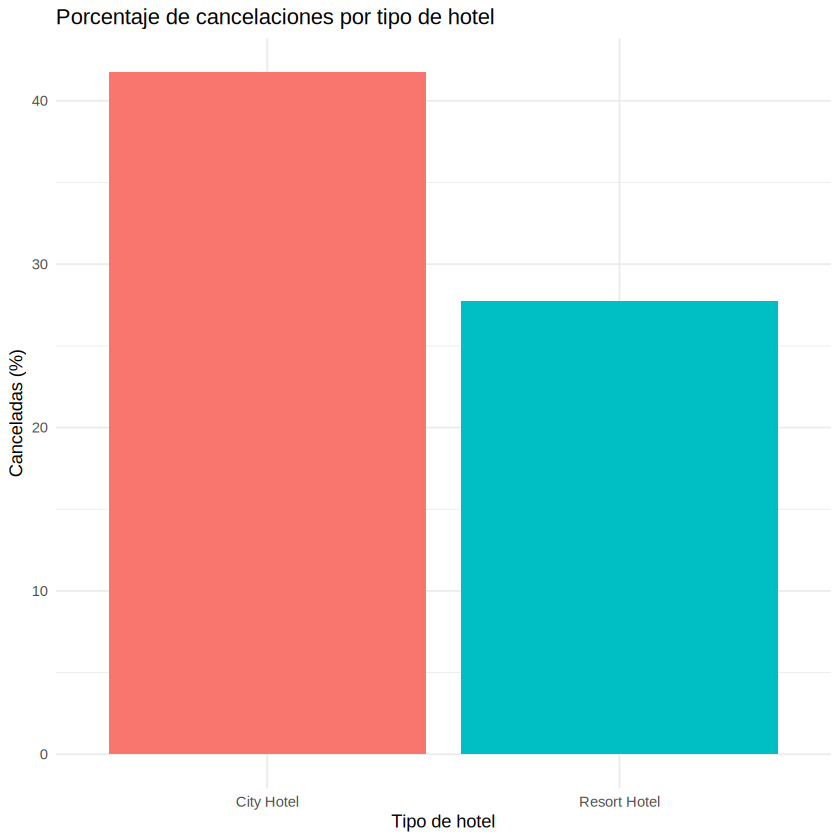

In [21]:
ggplot(comparacion_hotel,
       aes(x = hotel, y = porcentaje_canceladas, fill = hotel)) +
  geom_col(show.legend = FALSE) +
  labs(title = "Porcentaje de cancelaciones por tipo de hotel",
       x = "Tipo de hotel", y = "Canceladas (%)") +
  theme_minimal()


**Interpretación:** Tener más reservas no significa necesariamente tener una mayor proporción de cancelaciones. La diferencia observada no demuestra causalidad.


### Pregunta 2. ADR y cancelación

¿La distribución de la tarifa promedio por noche difiere entre reservas canceladas y no canceladas?


In [22]:
comparacion_adr <- DBI::dbGetQuery(
  conexion,
  "
  SELECT is_canceled,
         CASE WHEN is_canceled = 1 THEN 'Cancelada' ELSE 'No cancelada' END AS estado,
         COUNT(adr) AS cantidad,
         AVG(adr) AS media,
         MEDIAN(adr) AS mediana,
         STDDEV_SAMP(adr) AS desvio,
         QUANTILE_CONT(adr, 0.25) AS q1,
         QUANTILE_CONT(adr, 0.75) AS q3,
         MIN(adr) AS minimo,
         MAX(adr) AS maximo
  FROM reservas
  WHERE is_canceled IN (0, 1) AND adr IS NOT NULL
  GROUP BY is_canceled
  ORDER BY is_canceled
  "
)
comparacion_adr


is_canceled,estado,cantidad,media,mediana,desvio,q1,q3,minimo,maximo
<int>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
0,No cancelada,15738,100.3109,92.785,49.29924,68.0,125.1,0,510
1,Cancelada,9261,105.0359,96.000,46.74346,72.9,128.0,0,450


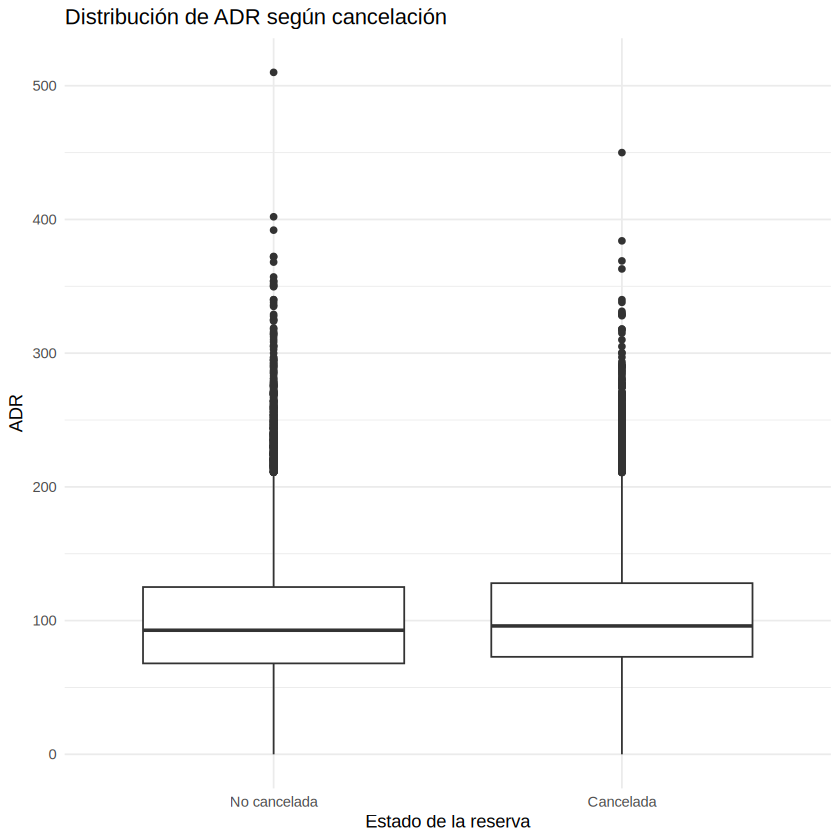

In [23]:
ggplot(df %>% filter(is_canceled %in% c(0, 1)),
       aes(x = factor(is_canceled, levels = c(0, 1),
                      labels = c("No cancelada", "Cancelada")),
           y = adr)) +
  geom_boxplot(na.rm = TRUE) +
  labs(title = "Distribución de ADR según cancelación",
       x = "Estado de la reserva", y = "ADR") +
  theme_minimal()


**Interpretación:** Las medianas difieren, cuánto se superponen los rangos intercuartílicos y si hay valores extremos. Una mediana cercana no alcanza para afirmar que ADR no se relaciona con cancelaciones. La comparación es descriptiva.


### Pregunta 3. Lead time y cancelación

¿La anticipación con la que se realiza la reserva difiere entre reservas canceladas y no canceladas?


In [24]:
comparacion_lead <- DBI::dbGetQuery(
  conexion,
  "
  SELECT is_canceled,
         CASE WHEN is_canceled = 1 THEN 'Cancelada' ELSE 'No cancelada' END AS estado,
         COUNT(lead_time) AS cantidad,
         AVG(lead_time) AS media,
         MEDIAN(lead_time) AS mediana,
         STDDEV_SAMP(lead_time) AS desvio,
         QUANTILE_CONT(lead_time, 0.25) AS q1,
         QUANTILE_CONT(lead_time, 0.75) AS q3,
         MIN(lead_time) AS minimo,
         MAX(lead_time) AS maximo
  FROM reservas
  WHERE is_canceled IN (0, 1) AND lead_time IS NOT NULL
  GROUP BY is_canceled
  ORDER BY is_canceled
  "
)
comparacion_lead


is_canceled,estado,cantidad,media,mediana,desvio,q1,q3,minimo,maximo
<int>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
0,No cancelada,15738,79.31974,44,90.96931,8,123,0,542
1,Cancelada,9261,145.72282,113,119.82249,48,218,0,629


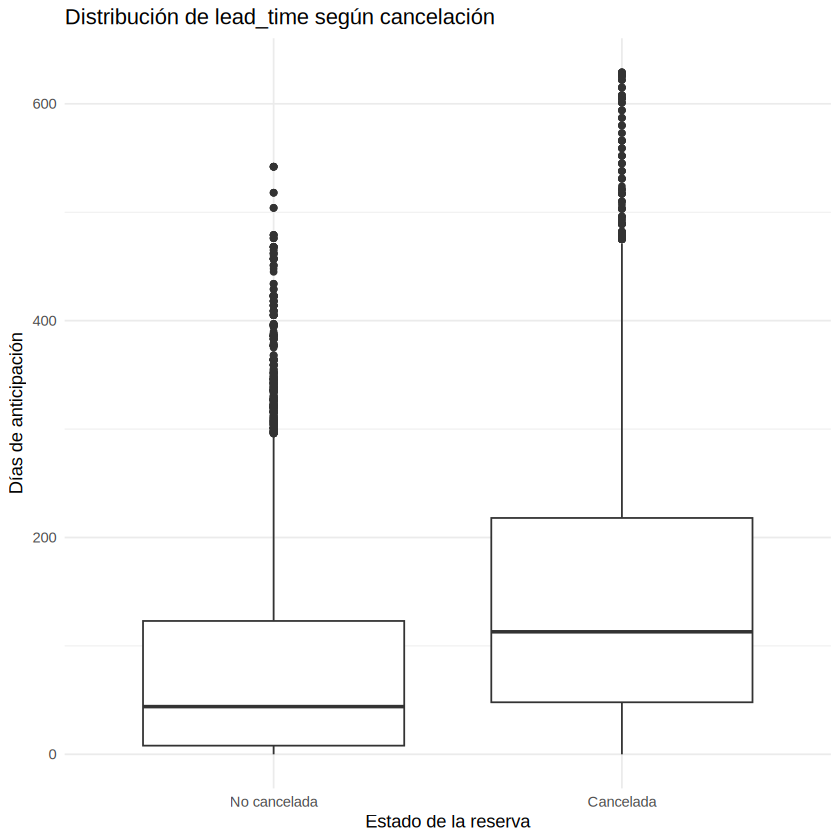

In [25]:
ggplot(df %>% filter(is_canceled %in% c(0, 1)),
       aes(x = factor(is_canceled, levels = c(0, 1),
                      labels = c("No cancelada", "Cancelada")),
           y = lead_time)) +
  geom_boxplot(na.rm = TRUE) +
  labs(title = "Distribución de lead_time según cancelación",
       x = "Estado de la reserva", y = "Días de anticipación") +
  theme_minimal()


**Interpretación:** En el boxplot la línea central es la **mediana**, la caja representa el rango intercuartílico y los puntos alejados pueden ser valores atípicos. Una mediana mayor en reservas canceladas sugeriría asociación con una mayor anticipación, pero el boxplot no muestra directamente una probabilidad de cancelación ni demuestra causalidad.


## 7. Patrones y casos llamativos

Se conservan los casos inusuales. Estas consultas permiten localizarlos para una revisión contextual, sin eliminarlos automáticamente.


In [26]:
# Reservas con anticipación de 365 días o más
casos_lead <- DBI::dbGetQuery(
  conexion,
  "
  SELECT hotel, lead_time, adr, is_canceled
  FROM reservas
  WHERE lead_time >= 365
  ORDER BY lead_time DESC
  LIMIT 20
  "
)
casos_lead


hotel,lead_time,adr,is_canceled
<chr>,<dbl>,<dbl>,<int>
City Hotel,629,62.0,1
City Hotel,629,62.0,1
City Hotel,629,62.0,1
City Hotel,629,59.0,1
City Hotel,626,62.8,1
City Hotel,626,62.8,1
City Hotel,626,62.8,1
City Hotel,626,62.8,1
City Hotel,626,62.8,1


In [27]:
# ADR igual a cero y valores iguales o superiores al percentil 99
casos_adr <- DBI::dbGetQuery(
  conexion,
  "
  SELECT hotel, adr, lead_time, is_canceled
  FROM reservas
  WHERE adr = 0
     OR adr >= (SELECT QUANTILE_CONT(adr, 0.99)
                FROM reservas WHERE adr IS NOT NULL)
  ORDER BY adr
  LIMIT 30
  "
)
casos_adr


hotel,adr,lead_time,is_canceled
<chr>,<dbl>,<dbl>,<int>
City Hotel,0,1,0
City Hotel,0,0,0
Resort Hotel,0,0,0
City Hotel,0,0,0
City Hotel,0,0,0
Resort Hotel,0,0,0
Resort Hotel,0,2,0
Resort Hotel,0,1,0
City Hotel,0,5,0


**Interpretación:** las consultas identifican reservas con anticipación muy alta o tarifas nulas/extremas. Un valor inusual no es necesariamente un error; debe revisarse junto con el contexto y otras variables. No se elimina ni modifica ningún registro por aparecer aquí.


## 8. Variables candidatas para etapas posteriores

| Variable | Justificación |
|---|---|
| `hotel` | Permite comparar tipos de establecimiento y sus tasas observadas de cancelación. |
| `lead_time` | Puede presentar distribuciones distintas entre los estados. |
| `adr` | Permite evaluar diferencias en nivel y variabilidad de tarifas. |
| `deposit_type` | Puede representar condiciones de garantía de la reserva. |
| `market_segment` | Caracteriza el segmento de mercado. |
| `distribution_channel` | Identifica el canal por el que se realizó la reserva. |
| `previous_cancellations` | Resume antecedentes de cancelaciones. |
| `customer_type` | Caracteriza el tipo de cliente. |
| `total_nights` | Resume la duración de la estadía. |

Su utilidad deberá evaluarse posteriormente, teniendo en cuenta la calidad de los datos y evitando información que no estaría disponible al momento de predecir.


## 9. Conclusiones exploratorias: tres hallazgos

Completar luego de ejecutar las consultas. Cada hallazgo debe incluir valores numéricos reales obtenidos del SQL.

**Hallazgo 1 – Tipo de hotel**   
En el conjunto de datos se observa una diferencia en los porcentajes de cancelación según el tipo de hotel. El City Hotel registró 16.611 reservas, de las cuales 6.933 fueron canceladas, lo que representa un 41,74 %. Por otro lado, el Resort Hotel registró 8.388 reservas, con 2.328 cancelaciones, equivalentes al 27,75 %. Esto representa una diferencia de 13,99 puntos porcentuales entre ambos tipos de hotel. En estos datos, las reservas del City Hotel presentan una mayor proporción de cancelaciones que las del Resort Hotel.

**Hallazgo 2 – ADR**     
Las reservas canceladas presentan un ADR promedio de 105,04, mientras que las no canceladas registran un promedio de 100,31. La diferencia entre ambos grupos es de aproximadamente 4,72 unidades. También se observa una mediana ligeramente superior en las reservas canceladas (96 frente a 92,79). Sin embargo, las distribuciones presentan una dispersión considerable y valores máximos elevados en ambos grupos. Esto sugiere una diferencia moderada en los valores de ADR según el estado de cancelación, pero no permite afirmar que un ADR más alto provoque una cancelación.

**Hallazgo 3 – Lead time**          
Las reservas canceladas presentan un lead time promedio de 145,72 días, mientras que las no canceladas tienen un promedio de 79,32 días. La diferencia también se observa en las medianas: 113 días para las canceladas y 44 días para las no canceladas. Además, el primer y tercer cuartil de las reservas canceladas (48 y 218 días) son superiores a los de las no canceladas (8 y 123 días). Estos resultados muestran una asociación entre una mayor anticipación de la reserva y una mayor presencia de cancelaciones. No obstante, no permiten establecer una relación causal.


## 10. Alcances y limitaciones

1. **No se puede afirmar causalidad:** las diferencias entre grupos no demuestran que el hotel, la tarifa o la anticipación provoquen una cancelación.
2. **No se controlan simultáneamente otras variables:** depósito, segmento, canal, tipo de cliente e historial podrían estar relacionados con los resultados.
3. **Los resultados describen este dataset:** no deben generalizarse automáticamente a todos los hoteles, destinos o períodos.
4. **Los valores extremos requieren contexto:** las consultas los localizan, pero no permiten clasificarlos automáticamente como errores.

Para profundizar será necesario analizar más variables conjuntamente y, en una etapa posterior, evaluar un modelo predictivo.


## 11. Verificación final


In [29]:
cat(
  "Filas en tabla SQL:",
  DBI::dbGetQuery(conexion, "SELECT COUNT(*) AS n FROM reservas")$n,
  "Columnas en tabla SQL:",
  nrow(DBI::dbGetQuery(conexion, "DESCRIBE reservas")),
  "Preguntas comparadas: hotel, adr y lead_time.",
  "Recorrido utilizado: SQL + R.",
  sep = "\n"
)

Filas en tabla SQL:
24999
Columnas en tabla SQL:
33
Preguntas comparadas: hotel, adr y lead_time.
Recorrido utilizado: SQL + R.


## 12. Antes de entregar

1. Ejecutar todas las celdas en orden.
2. Subir el CSV original y verificar que se cargue correctamente.
3. Revisar que las consultas SQL y los gráficos se generen sin errores.
4. Completar los tres hallazgos con números reales de las tablas.
5. Confirmar que cada interpretación coincida con los resultados.
6. Guardar el notebook con las salidas visibles.

**Nombre sugerido:** `Aguillon_Fernando_Comision5_Entrega4.ipynb`.
